# 基于朴素贝叶斯的乳腺癌分类研究
**张峻珲2026104383期末大作业**

数据：UCI Wisconsin Diagnostic Breast Cancer（通过 `sklearn.datasets` 获取）。

## 一、探索性数据分析

### 1.1 导入模块

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             RocCurveDisplay, ConfusionMatrixDisplay, brier_score_loss)

SEED = 42
OUT = Path('bayes_results')
OUT.mkdir(exist_ok=True)

### 1.2 类的定义
`CancerDataProject`负责加载和整理数据

In [21]:
class CancerDataset:
    def load(self):
        raw = load_breast_cancer(as_frame=True)
        data = raw.data.copy()
        data['malignant'] = (raw.target == 0).astype(int).to_numpy()
        return data.drop_duplicates()

### 1.3 异常处理
对数据完整性进行检查；异常会明确提示并停止运行。

In [22]:
try:
    data = CancerDataset().load()
    if data.empty or data.isna().any().any():
        raise ValueError('数据为空或存在缺失值')
    if data['malignant'].nunique() != 2:
        raise ValueError('类别数量异常')
except (ValueError, OSError) as e:
    print('数据加载失败：', e)
    raise
else:
    print('数据检查通过，形状：', data.shape)

数据检查通过，形状： (569, 31)


### 1.4 数据基本信息与清洗结果

In [23]:
print('缺失值：', data.isna().sum().sum(), '；重复行：', data.duplicated().sum())
print('类别分布（0=良性，1=恶性）：')
print(data['malignant'].value_counts().sort_index())
display(data.head())
display(data.describe().round(2).iloc[:, :6])
data.to_csv(OUT / 'wdbc_clean.csv', index=False)

缺失值： 0 ；重复行： 0
类别分布（0=良性，1=恶性）：
malignant
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


### 1.5 探索性可视化：类别分布、特征相关性

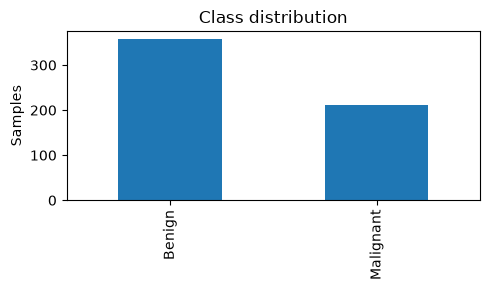

In [24]:
fig, ax = plt.subplots(figsize=(5, 3))
data.malignant.value_counts().sort_index().plot.bar(ax=ax)
ax.set(xticklabels=['Benign', 'Malignant'], xlabel='', ylabel='Samples', title='Class distribution')
plt.tight_layout(); plt.savefig(OUT / '01_classes.png', dpi=150); plt.show()

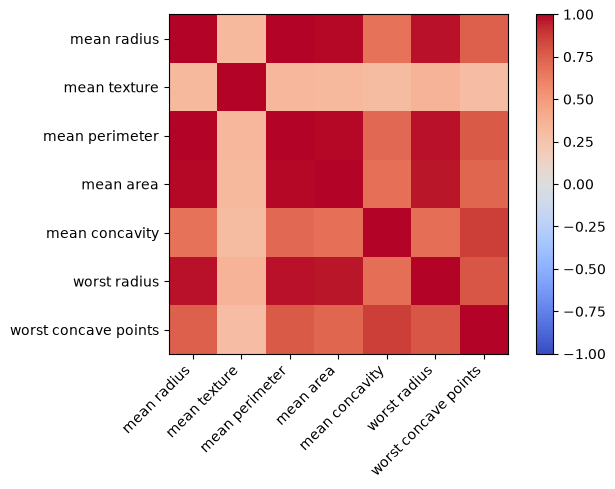

In [25]:
features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area',
            'mean concavity', 'worst radius', 'worst concave points']
corr = data[features].corr()
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=45, ha='right')
ax.set_yticks(range(len(features)), features)
fig.colorbar(im, ax=ax); plt.tight_layout()
plt.savefig(OUT / '02_correlation.png', dpi=150); plt.show()

## 二、机器学习模型构建与调整参数
`GaussianNB`、`LogisticRegression` 使用标准化，随机森林无需标准化。

### 2.1 模型构建

In [26]:
def get_models(seed=42):
    return {
        'GaussianNB': (make_pipeline(StandardScaler(), GaussianNB()),
                       {'gaussiannb__var_smoothing': [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4, 1e-2]}),
        'LogisticRegression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=seed)),
                               {'logisticregression__C': [.01, .1, 1, 10, 100]}),
        'RandomForest': (RandomForestClassifier(random_state=seed, n_jobs=1),
                         {'n_estimators': [100, 200], 'max_depth': [3, None], 'min_samples_leaf': [1, 3]})
    }

### 2.2 模型训练

In [27]:
def fit_evaluate(name, model, params, X_tr, X_te, y_tr, y_te, cv):
    search = GridSearchCV(model, params, scoring='roc_auc', cv=cv, n_jobs=1)
    search.fit(X_tr, y_tr)
    pred = search.predict(X_te)
    prob = search.predict_proba(X_te)[:, 1]
    row = {'model': name, 'cv_auc': search.best_score_,
           'test_accuracy': accuracy_score(y_te, pred),
           'test_precision': precision_score(y_te, pred),
           'test_recall': recall_score(y_te, pred),
           'test_f1': f1_score(y_te, pred),
           'test_auc': roc_auc_score(y_te, prob),
           'test_brier': brier_score_loss(y_te, prob),
           'best_params': str(search.best_params_)}
    history = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'rank_test_score']]
    history.insert(0, 'model', name)
    return row, history, (pred, prob)

### 2.3 划分数据、训练与调参

In [28]:
X, y = data.drop(columns='malignant'), data.malignant
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows, logs, predictions = [], [], {}
for name, (model, params) in get_models(SEED).items():
    row, log, predictions[name] = fit_evaluate(
        name, model, params, X_train, X_test, y_train, y_test, cv)
    rows.append(row)
    logs.append(log)

results = pd.DataFrame(rows)
tuning = pd.concat(logs, ignore_index=True)
results.to_csv(OUT / 'model_comparison.csv', index=False)
tuning.to_csv(OUT / 'tuning_results.csv', index=False)
print('训练集：', len(X_train), '测试集：', len(X_test))
display(results.round(4))

训练集： 455 测试集： 114


,model,cv_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc,test_brier,best_params
0,GaussianNB,0.9870,0.9211,0.9231,0.8571,0.8889,0.9891,0.0757,{'gaussiannb__var_smoothing': 1e-12}
1,LogisticRegression,0.9958,0.9649,0.9750,0.9286,0.9512,0.9960,0.0213,{'logisticregression__C': 1}
2,RandomForest,0.9889,0.9737,1.0000,0.9286,0.9630,0.9929,0.0324,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."


### 2.4 最优参数与调参记录

In [29]:
display(results[['model', 'best_params']])
for name, group in tuning.groupby('model', sort=False):
    print(name)
    display(group.nsmallest(3, 'rank_test_score'))

,model,best_params
0,GaussianNB,{'gaussiannb__var_smoothing': 1e-12}
1,LogisticRegression,{'logisticregression__C': 1}
2,RandomForest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."


GaussianNB


,model,params,mean_test_score,rank_test_score
0,GaussianNB,{'gaussiannb__var_smoothing': 1e-12},0.986997,1
1,GaussianNB,{'gaussiannb__var_smoothing': 1e-10},0.986997,1
2,GaussianNB,{'gaussiannb__var_smoothing': 1e-09},0.986997,1


LogisticRegression


,model,params,mean_test_score,rank_test_score
9,LogisticRegression,{'logisticregression__C': 1},0.995769,1
8,LogisticRegression,{'logisticregression__C': 0.1},0.994943,2
10,LogisticRegression,{'logisticregression__C': 10},0.994324,3


RandomForest


,model,params,mean_test_score,rank_test_score
16,RandomForest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.988906,1
17,RandomForest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.988854,2
14,RandomForest,"{'max_depth': 3, 'min_samples_leaf': 3, 'n_est...",0.988338,3


## 三、模型结果比较

### 3.1 ROC曲线

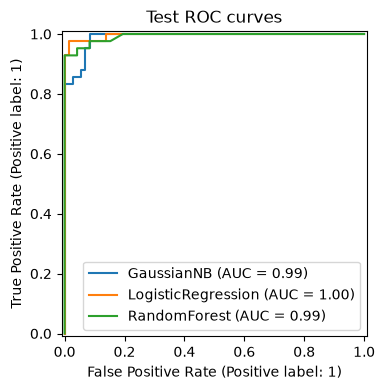

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, (_, prob) in predictions.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.set_title('Test ROC curves'); plt.tight_layout()
plt.savefig(OUT / '03_roc.png', dpi=150); plt.show()

### 3.2 混淆矩阵

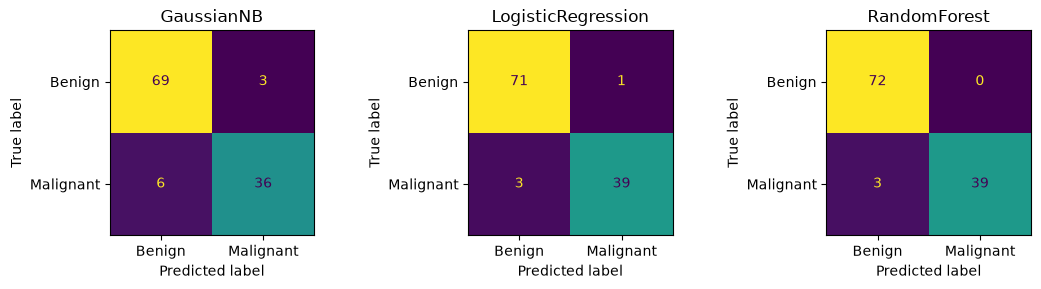

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (name, (pred, _)) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax,
        display_labels=['Benign', 'Malignant'], colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(OUT / '04_confusion.png', dpi=150); plt.show()

### 3.3 交叉验证与测试集AUC比较

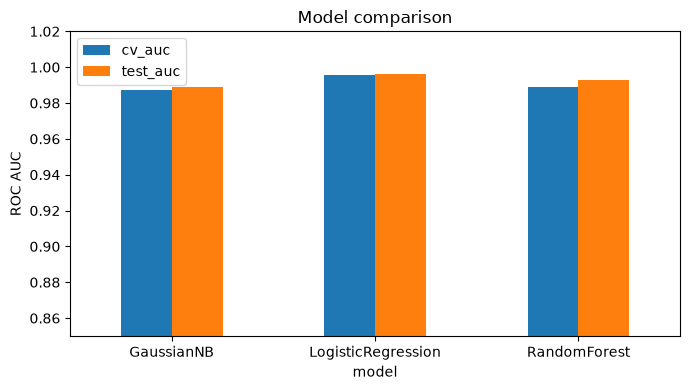

In [32]:
results.set_index('model')[['cv_auc', 'test_auc']].plot.bar(figsize=(7, 4))
plt.ylim(.85, 1.02); plt.ylabel('ROC AUC'); plt.title('Model comparison')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT / '05_auc.png', dpi=150); plt.show()

### 3.4 概率误差

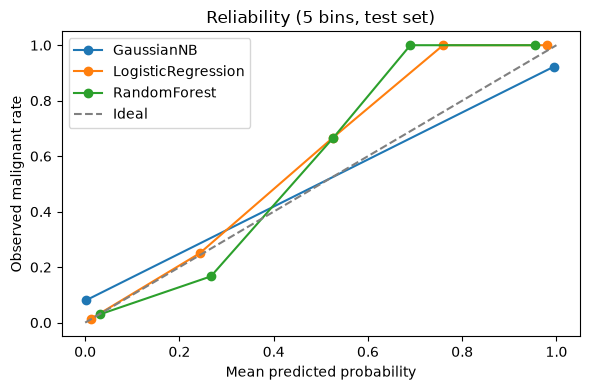

In [33]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, (_, prob) in predictions.items():
    bins = np.minimum((prob * 5).astype(int), 4)
    points = [(prob[bins == i].mean(), y_test.to_numpy()[bins == i].mean())
              for i in range(5) if (bins == i).any()]
    ax.plot(*np.array(points).T, 'o-', label=name)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
ax.set(xlabel='Mean predicted probability', ylabel='Observed malignant rate',
       title='Reliability (5 bins, test set)')
ax.legend(); plt.tight_layout()
plt.savefig(OUT / '06_reliability.png', dpi=150); plt.show()